In [1]:
#librerias basicas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.options.display.max_columns=None
import yaml

pd.options.display.max_rows=None

In [15]:
import importlib

In [21]:
from pathlib import Path

In [22]:
pwd

'f:\\06 proyectos git\\exp_modelo4\\notebooks'

In [23]:
#nombre de proyecto
nombre_exp='exp_modelo4' #colocar nombre de la carepta que contiene el proyecto

In [25]:
##ruta actual
ruta_actual = Path.cwd()
#Buscar la carpeta del proyecto en la ruta actual
partes = ruta_actual.parts
ruta_raiz = ruta_actual
for i, p in enumerate(partes):
    if p == nombre_exp:
        ruta_raiz = Path(*partes[:i + 1])
        break
ruta_raiz = str(ruta_raiz)

In [26]:
ruta_raiz

'f:\\06 proyectos git\\exp_modelo4'

In [27]:
#cargando metadata archivo configuracion .yaml
config_path = Path(ruta_raiz) / 'config' / 'model' / 'archivo_config.yaml'
with open(config_path, 'r', encoding='utf-8') as file:
    config = yaml.safe_load(file)


In [28]:
###permite cargar modulos scripts.py
import sys
import os
dir=os.path.abspath(config['settings']['ruta_src'])
if dir not in sys.path:
    sys.path.append(dir)

In [29]:
from prep_EDA import validar_numerico

In [11]:
#recarga modulo cargado en memoria para no reiniciar kernel
importlib.reload(sys.modules['prep_detect_asimetria'])

NameError: name 'importlib' is not defined

In [30]:
#rutas data
path_data_pro=config['settings']['ruta_data_pro']
path_raiz=config['settings']['ruta_raiz']
path_data_raw=config['settings']['ruta_data_raw']
path_data_final=config['settings']['ruta_data_final']
path_models=config['settings']['ruta_models']

In [31]:
path_data_raw

'f:\\06 proyectos git\\exp_modelo4\\Data\\raw'

In [32]:
Path(path_data_raw) 

WindowsPath('f:/06 proyectos git/exp_modelo4/Data/raw')

In [34]:
df = pd.read_csv(Path(path_data_raw) / "base_churn_telcov2.csv")

In [ ]:
#servidor
df = pd.read_csv(path_data_raw + "base_churn_telcov2.csv")

In [35]:
df.head(5)

,PERIODO,CUSTOMER_ID,ANTIGUEDAD_MESES,EDAD_CLIENTE,VELOCIDAD_PLAN,RENTA_MENSUAL,CONSUMO_GB,RECLAMOS_3M,RECLAMOS_12M,TICKETS_TECNICOS,CAIDAS_SERVICIO,DIAS_MORA,PAGOS_ATRASADOS_12M,SATISFACCION,VISITAS_WEB,VISITAS_APP,CAMPANIAS_RECIBIDAS,CAMPANIAS_RESPONDIDAS,VELOCIDAD_REAL,USO_STREAMING,USO_GAMING,N_PRODUCTOS,TENURE_ULTIMO_UPGRADE,INGRESO_HOGAR,COMPETENCIA_ZONA,SCORE_RIESGO,CONTACTOS_CALLCENTER,INTERACCIONES_DIGITALES,VELOCIDAD_VARIABILIDAD,DESCUENTO_PCT,USO_NOCTURNO,USO_FIN_SEMANA,SEGMENTO,TECNOLOGIA,REGION,SEXO,CANAL_VENTA,CHURN_VOLUNTARIO,DISTRITO,FLAG_PREMIUM_FALSO,RENTA_MENSUAL_2,FLAG_RETENCION_EXITOSA,YEAR,FLAG_EMPRESA,FLAG_CASI_CONSTANTE,RENTA_MENSUAL_3,ID_CONTRATO,RECLAMOS_RED_SOCIAL
0,2023-01-01,CUST_000001,113,71.0,50,4.104834,367.997453,2,3,1,0,0,2,7.527282,21,11,7,1,41.457487,53,52,2,48,3876.011607,2,0.253798,3,7,4.408812,36.683128,99.827743,78.052058,Masivo,Fibra,Lima,M,Call Center,0,DIST_388,1,9.349668,0,2023,1,1,5.200272,CONT_0,0.302734
1,2023-02-01,CUST_000001,114,71.0,50,1.757508,323.404792,2,6,1,0,3,3,8.790275,14,11,3,2,150.000000,96,5,2,40,3619.095364,2,0.591510,1,7,24.756448,5.708874,30.954199,56.910698,Masivo,Fibra,Lima,M,Call Center,0,DIST_233,1,-1.562136,0,2023,1,1,0.909783,CONT_1,1.886790
2,2023-03-01,CUST_000001,115,71.0,50,6.830930,385.972005,1,4,1,0,5,1,6.531012,11,6,3,2,53.427387,34,37,2,34,NaN,2,0.601026,3,6,27.236718,14.527568,28.715226,50.073491,Masivo,Fibra,Lima,M,Call Center,0,DIST_121,1,9.173178,1,2023,1,1,3.388333,CONT_2,1.073655
3,2023-04-01,CUST_000001,116,71.0,50,-11.446290,363.553714,3,5,1,6,2,2,7.767388,14,15,1,1,40.719442,53,89,2,16,3690.253173,2,0.958565,3,6,0.767369,31.868347,60.014048,71.092964,Masivo,Fibra,Lima,M,Call Center,0,DIST_203,1,-15.310123,0,2023,1,1,-9.044153,CONT_3,2.436723
4,2023-05-01,CUST_000001,117,71.0,50,-11.588707,390.446332,1,3,0,1,4,1,6.245754,11,15,4,4,NaN,74,84,2,29,NaN,2,0.764246,1,7,9.918989,3.612742,56.265412,47.904073,Masivo,Fibra,Lima,M,Call Center,0,DIST_87,1,-8.563236,0,2023,1,1,-11.721606,CONT_4,0.047751


In [36]:
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency
from scipy.stats import ks_2samp

import warnings
warnings.filterwarnings("ignore")

TARGET = "CHURN_VOLUNTARIO"
ID_COL = "CUSTOMER_ID"
DATE_COL = "PERIODO"

df[DATE_COL] = pd.to_datetime(df[DATE_COL])

num_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

cat_cols = df.select_dtypes(
    include=["object","category"]
).columns.tolist()

# excluir target y id

num_cols = [
    c for c in num_cols
    if c != TARGET
]

cat_cols = [
    c for c in cat_cols
    if c != ID_COL
]

In [37]:
#1. Cantidad de variables y filas
print("Filas :", len(df))
print("Columnas :", len(df.columns))

print("\nVariables Numéricas")
print(len(num_cols))

print("\nVariables Categóricas")
print(len(cat_cols))

Filas : 23626
Columnas : 48

Variables Numéricas
38

Variables Categóricas
7


In [38]:
#2. Análisis de nulos
nulos = pd.DataFrame({

    "feature":df.columns,

    "nulos":
        df.isnull().sum(),

    "pct_nulos":
        round(
            100*df.isnull().mean(),
            2
        )

})

nulos.sort_values(
    "pct_nulos",
    ascending=False
)

,feature,nulos,pct_nulos
VELOCIDAD_REAL,VELOCIDAD_REAL,9392,39.75
INGRESO_HOGAR,INGRESO_HOGAR,4522,19.14
EDAD_CLIENTE,EDAD_CLIENTE,2313,9.79
SATISFACCION,SATISFACCION,60,0.25
CANAL_VENTA,CANAL_VENTA,0,0.00
VELOCIDAD_VARIABILIDAD,VELOCIDAD_VARIABILIDAD,0,0.00
DESCUENTO_PCT,DESCUENTO_PCT,0,0.00
USO_NOCTURNO,USO_NOCTURNO,0,0.00
USO_FIN_SEMANA,USO_FIN_SEMANA,0,0.00
SEGMENTO,SEGMENTO,0,0.00


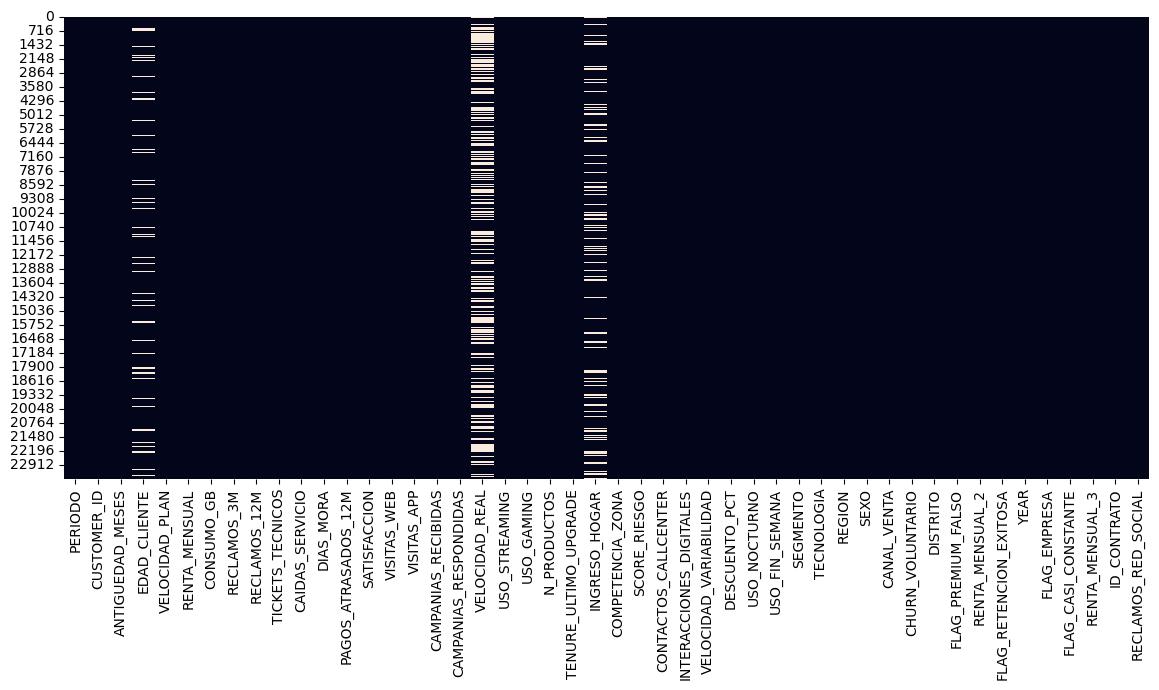

In [39]:
#Heatmap de nulos
plt.figure(figsize=(14,6))

sns.heatmap(
    df.isnull(),
    cbar=False
)

plt.show()

In [40]:
#Detección MCAR / MAR / MNAR
#Ejemplo para INGRESO_HOGAR.
missing_flag = (
    df["INGRESO_HOGAR"]
    .isnull()
    .astype(int)
)

In [41]:
#Cruzar contra variables.
for col in num_cols[:10]:

    corr = np.corrcoef(
        missing_flag,
        df[col].fillna(
            df[col].median()
        )
    )[0,1]

    print(
        col,
        round(corr,3)
    )

ANTIGUEDAD_MESES 0.007
EDAD_CLIENTE -0.018
VELOCIDAD_PLAN -0.002
RENTA_MENSUAL -0.003
CONSUMO_GB 0.007
RECLAMOS_3M 0.002
RECLAMOS_12M 0.005
TICKETS_TECNICOS -0.004
CAIDAS_SERVICIO 0.004
DIAS_MORA 0.006


In [42]:
#Si todas las correlaciones están cerca de cero:
#MCAR probable